In [7]:
import pandas as pd
df= pd.read_csv(r'C:\Users\HAI\GUVI\Planetary_defense\pha_dataset.csv')
df.head()

C:\Users\HAI\AppData\Local\Temp\ipykernel_1288\481796315.py:2: DtypeWarning: Columns (3,4,5) have mixed types. Specify dtype option on import or set low_memory=False.
  df= pd.read_csv(r'C:\Users\HAI\GUVI\Planetary_defense\pha_dataset.csv')


,id,spkid,full_name,pdes,name,prefix,neo,pha,H,diameter,...,sigma_i,sigma_om,sigma_w,sigma_ma,sigma_ad,sigma_n,sigma_tp,sigma_per,class,rms
0,a0000001,2000001,1 Ceres,1,Ceres,NaN,N,N,3.40,939.400,...,4.608900e-09,6.168800e-08,6.624800e-08,7.820700e-09,1.111300e-11,1.196500e-12,3.782900e-08,9.415900e-09,MBA,0.43301
1,a0000002,2000002,2 Pallas,2,Pallas,NaN,N,N,4.20,545.000,...,3.469400e-06,6.272400e-06,9.128200e-06,8.859100e-06,4.961300e-09,4.653600e-10,4.078700e-05,3.680700e-06,MBA,0.35936
2,a0000003,2000003,3 Juno,3,Juno,NaN,N,N,5.33,246.596,...,3.223100e-06,1.664600e-05,1.772100e-05,8.110400e-06,4.363900e-09,4.413400e-10,3.528800e-05,3.107200e-06,MBA,0.33848
3,a0000004,2000004,4 Vesta,4,Vesta,NaN,N,N,3.00,525.400,...,2.170600e-07,3.880800e-07,1.789300e-07,1.206800e-06,1.648600e-09,2.612500e-10,4.103700e-06,1.274900e-06,MBA,0.39980
4,a0000005,2000005,5 Astraea,5,Astraea,NaN,N,N,6.90,106.699,...,2.740800e-06,2.894900e-05,2.984200e-05,8.303800e-06,4.729000e-09,5.522700e-10,3.474300e-05,3.490500e-06,MBA,0.52191


In [8]:
df_reg = df.drop(['id', 'spkid', 'full_name', 'pdes', 'name', 'prefix','moid','q','equinox','orbit_id'],axis=1)

In [9]:
df_reg.isnull().sum()

neo                    4
pha                19921
H                   6263
diameter          822315
albedo            823421
diameter_sigma    822443
epoch                  0
epoch_mjd              0
epoch_cal              0
e                      0
a                      0
i                      0
om                     0
w                      0
ma                     1
ad                     4
n                      0
tp                     0
tp_cal                 0
per                    4
per_y                  1
moid_ld              127
sigma_e            19922
sigma_a            19922
sigma_q            19922
sigma_i            19922
sigma_om           19922
sigma_w            19922
sigma_ma           19922
sigma_ad           19926
sigma_n            19922
sigma_tp           19922
sigma_per          19926
class                  0
rms                    2
dtype: int64

In [10]:
df_reg.shape

(958524, 35)

In [11]:
df_reg = df_reg[df_reg['diameter'].notna()].copy()
df_reg.isnull().sum()

neo                  0
pha                  0
H                 4164
diameter             0
albedo            1109
diameter_sigma     128
epoch                0
epoch_mjd            0
epoch_cal            0
e                    0
a                    0
i                    0
om                   0
w                    0
ma                   0
ad                   0
n                    0
tp                   0
tp_cal               0
per                  0
per_y                0
moid_ld              0
sigma_e              0
sigma_a              0
sigma_q              0
sigma_i              0
sigma_om             0
sigma_w              0
sigma_ma             0
sigma_ad             0
sigma_n              0
sigma_tp             0
sigma_per            0
class                0
rms                  0
dtype: int64

In [12]:
df_reg.drop(columns=['diameter_sigma'], inplace=True)

#### Impute missing values in H and albedo

In [13]:
from sklearn.impute import SimpleImputer

cols = ['H', 'albedo']

imputer = SimpleImputer(strategy='median')

df_reg[cols] = imputer.fit_transform(df_reg[cols])

In [14]:
df_reg[['H', 'diameter', 'albedo']].isnull().sum()

H           0
diameter    0
albedo      0
dtype: int64

In [17]:
sigma_cols = [
    col for col in df_reg.columns
    if col.startswith('sigma_') or col == 'diameter_sigma'
]

df_reg.drop(columns=sigma_cols, inplace=True)

In [18]:
import seaborn as sns

num_cols = df_reg.select_dtypes(include='number').columns.tolist()
len(num_cols)

20

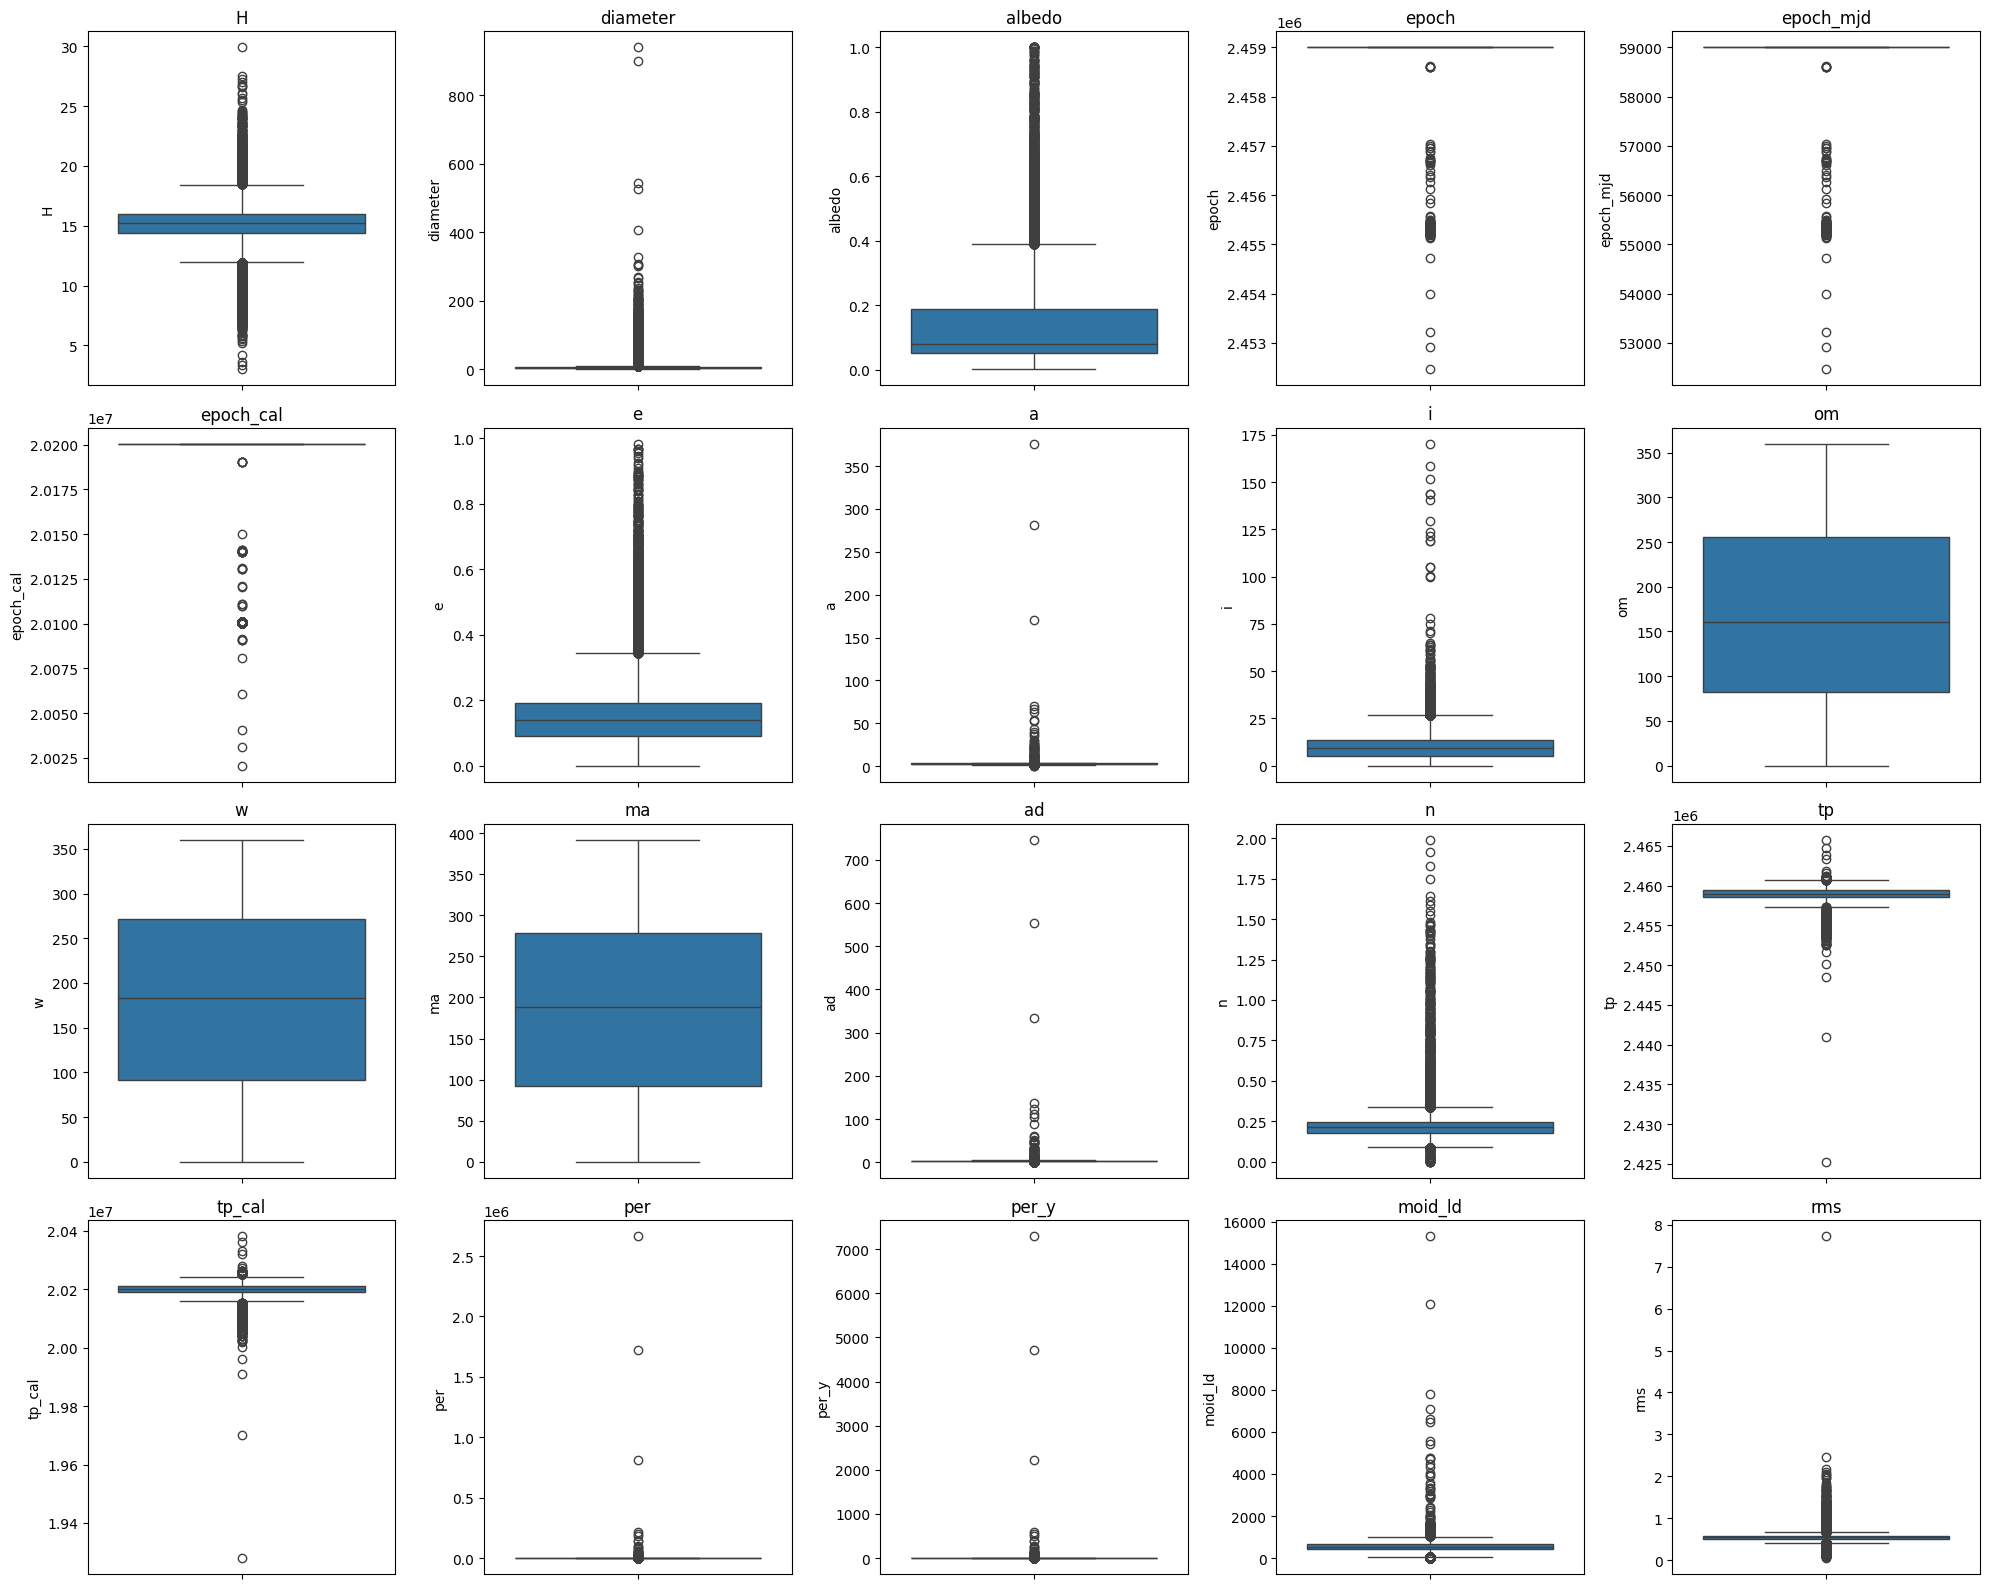

In [22]:
import seaborn as sns
import matplotlib.pyplot as plt
import math

num_cols = df_reg.select_dtypes(include='number').columns.tolist()

n_cols = 5
n_rows = math.ceil(len(num_cols) / n_cols)

fig, ax = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))

# Convert axes into a 1D array for easy iteration
ax = ax.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df_reg[col], ax=ax[i])
    ax[i].set_title(col)

# Hide unused plots
for j in range(len(num_cols), len(ax)):
    ax[j].set_visible(False)

plt.tight_layout()
plt.show()

In [24]:
df_reg[num_cols].skew()

H             -0.702615
diameter      25.852418
albedo         1.696635
epoch         -5.317796
epoch_mjd     -5.317796
epoch_cal     -5.315703
e              1.407371
a            174.781076
i              1.659299
om             0.185611
w             -0.027659
ma            -0.069455
ad           199.089250
n              6.026977
tp            -3.168572
tp_cal        -3.099067
per          249.879621
per_y        249.879621
moid_ld        7.601012
rms            8.741995
dtype: float64

In [25]:
import numpy as np

for col in num_cols:

    Q1 = df_reg[col].quantile(0.25)  # 25th percentile
    Q3 = df_reg[col].quantile(0.75)  # 75th percentile
    IQR = Q3 - Q1  # Interquartile range

    # Define lower and upper bound
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Cap values at lower and upper bound
    df_reg[col] = np.where(df_reg[col] < lower_bound, lower_bound, df_reg[col])
    df_reg[col] = np.where(df_reg[col] > upper_bound, upper_bound, df_reg[col])

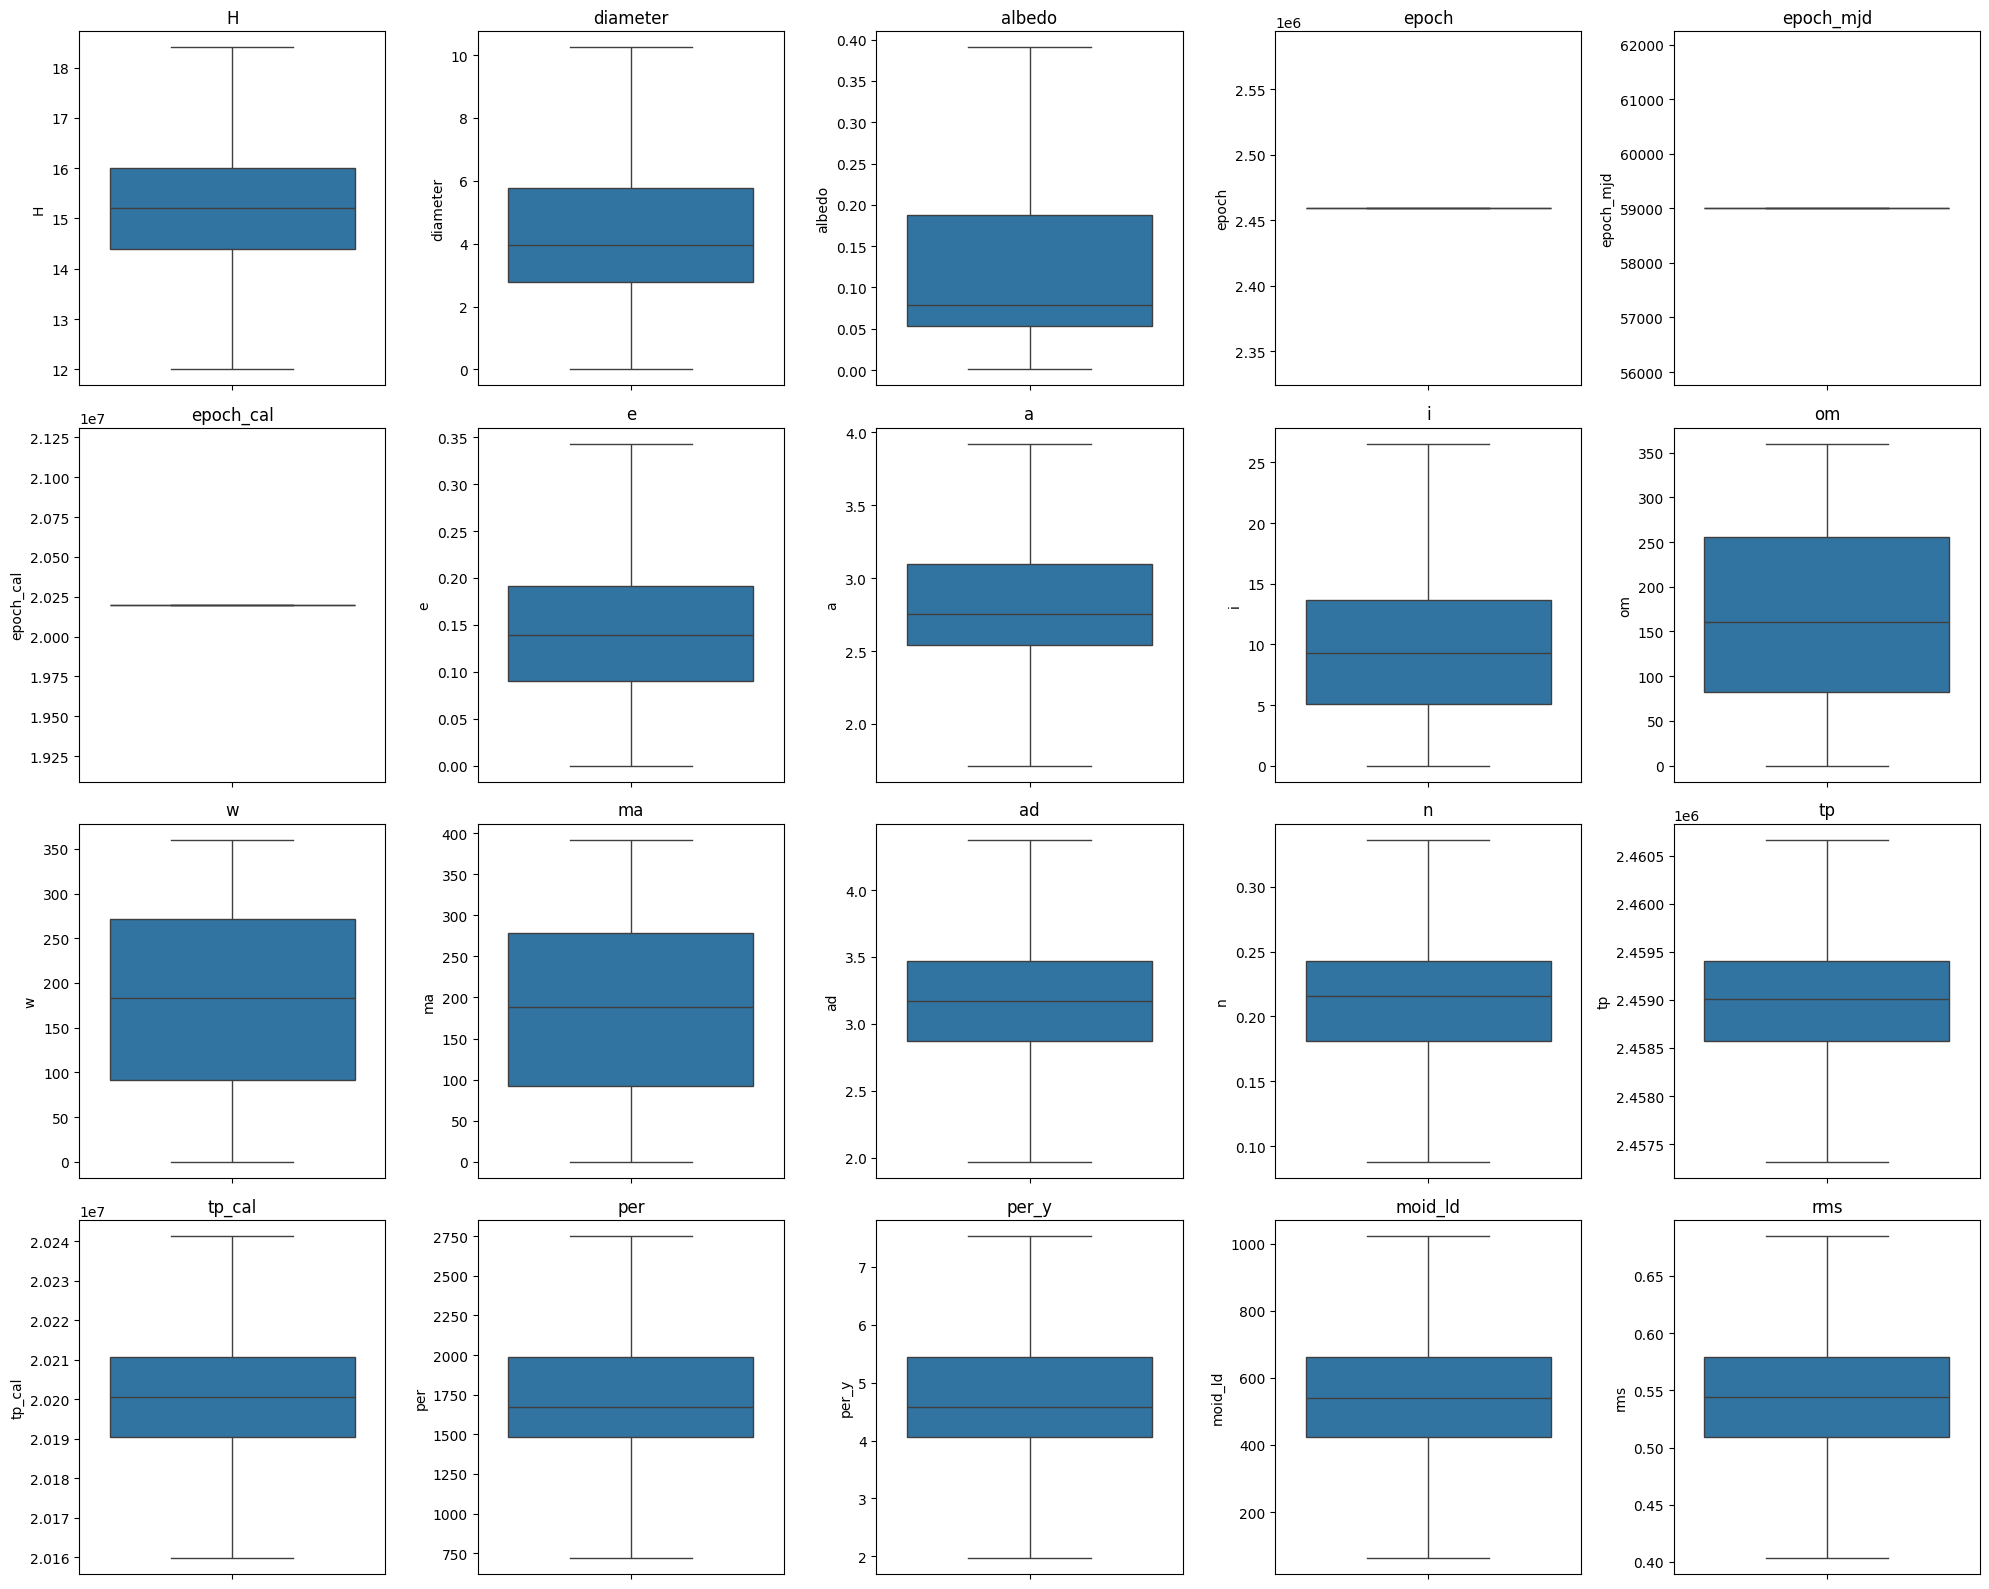

In [26]:
n_cols = 5
n_rows = math.ceil(len(num_cols) / n_cols)

fig, ax = plt.subplots(n_rows, n_cols, figsize=(20, 4 * n_rows))

# Convert axes into a 1D array for easy iteration
ax = ax.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(y=df_reg[col], ax=ax[i])
    ax[i].set_title(col)

# Hide unused plots
for j in range(len(num_cols), len(ax)):
    ax[j].set_visible(False)

plt.tight_layout()
plt.show()

In [28]:
df_reg[num_cols].skew()

H           -0.332029
diameter     0.958134
albedo       1.157281
epoch        0.000000
epoch_mjd    0.000000
epoch_cal    0.000000
e            0.436496
a            0.310997
i            0.825508
om           0.185611
w           -0.027659
ma          -0.069455
ad           0.319273
n            0.166937
tp          -0.566134
tp_cal      -0.348643
per          0.383994
per_y        0.383994
moid_ld      0.263419
rms         -0.057789
dtype: float64

In [29]:
df_reg.duplicated().sum()

np.int64(0)

In [31]:
df_reg.to_csv(r'C:\Users\HAI\GUVI\Planetary_defense\regression\cleaned.csv',index=False)